# HW4 -- Training Transformer


### Description
In this assignment, we are tasked with utilizing a transformer decoder-only architecture for pretraining, with a focus on next-token prediction, applied to Pokémon images.

## Activate GPU

To enable GPU, please follow these steps:

1. Click on "Runtime" in the header.
2. Click on "Change runtime type" in the drop menu.
3. Select "T4 GPU" and save. (You can select "A100 GPU" or "V100 GPU" if you have Colab Pro)
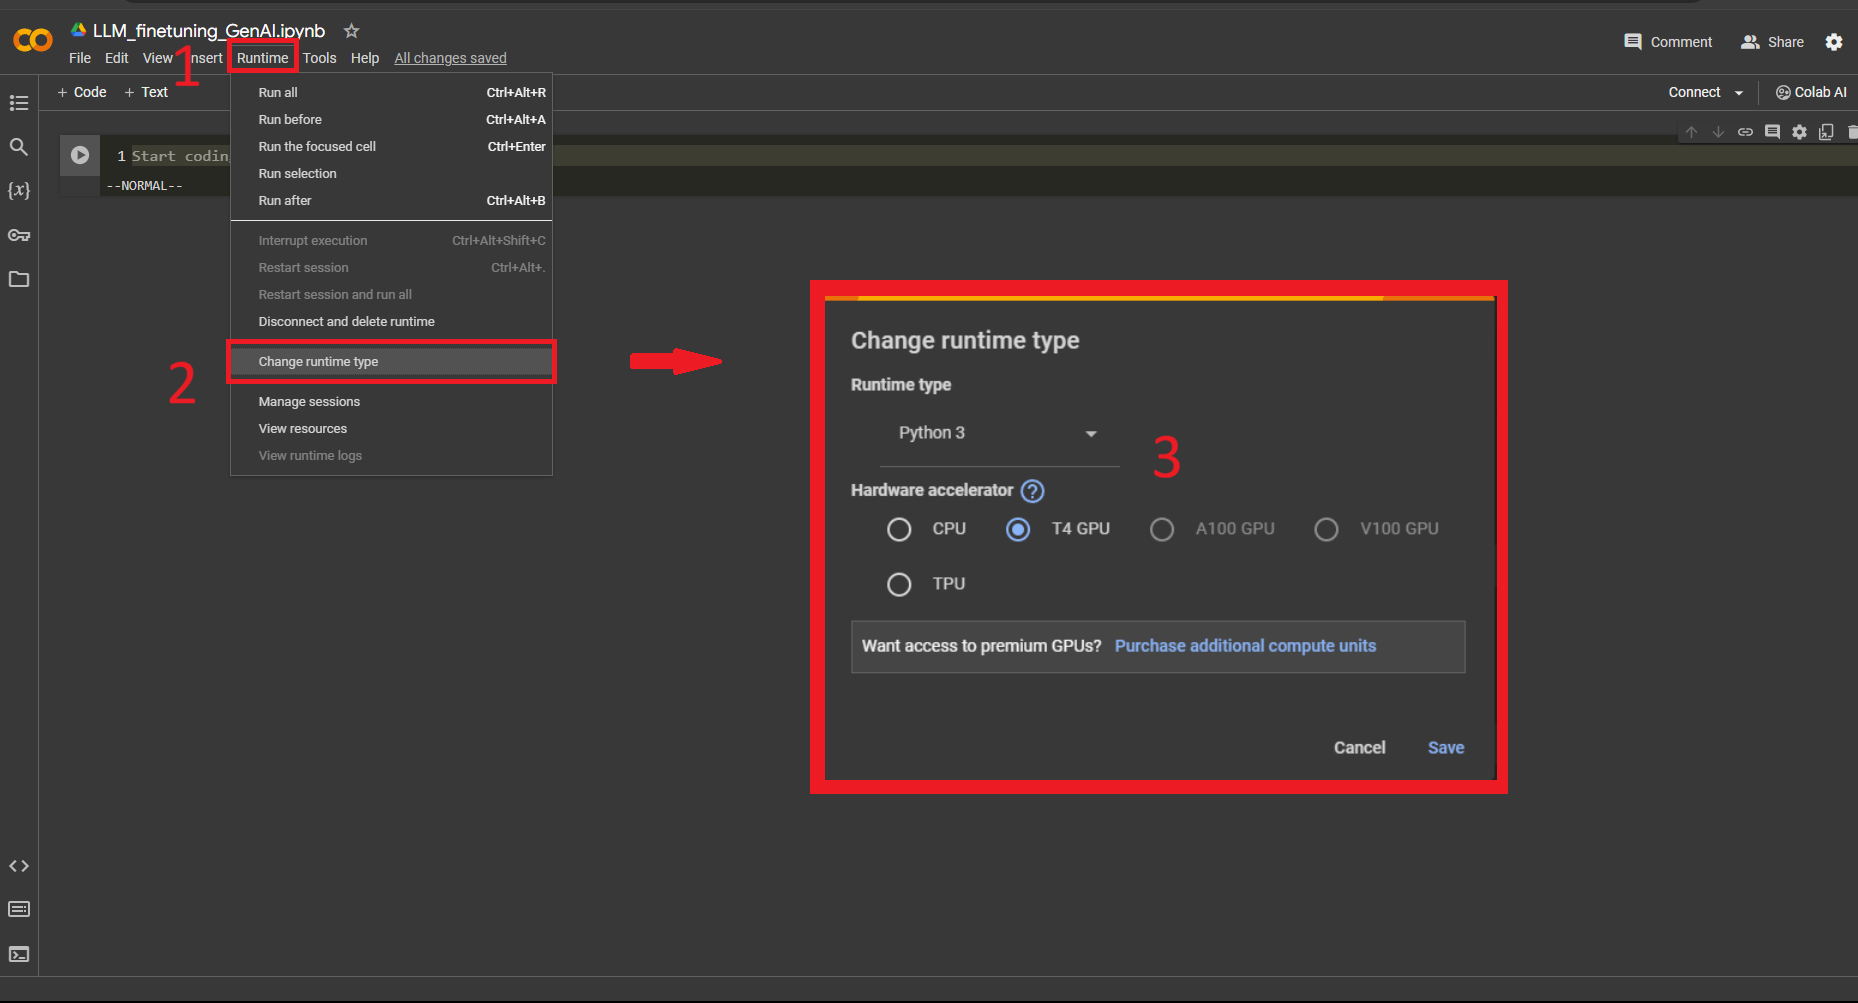

## Mount Google Drive

To mount Google Drive, please follow these steps:

1. Run the next cell.
2. Click on "Connect to Google Drive".
3. Sign in your account.

In [49]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# Utilities

### Download packages

In [50]:
!pip install datasets==3.3.2

### Import Packages

In [51]:
import math
import os
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.optim as optim
from PIL import Image
from torch import nn
from torch.utils.data import DataLoader, Dataset
from tqdm import tqdm
from transformers import AutoModelForCausalLM, GPT2Config, LlamaConfig, set_seed
from datasets import load_dataset
from typing import Dict, Any, Optional

### Check Devices

Ensure that you have already activated the GPU session. If not, check the "Activate GPU" block and follow the steps to activate GPU session.

In [52]:
!nvidia-smi

Wed Oct 28 02:05:41 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   78C    P0             34W /   70W |    4229MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

### Set Random Seed

We fix the random seed for reproducibility.

In [53]:
set_seed(0)

# Prepare Data

### Define Dataset

In [54]:
from typing import List, Tuple, Union
import random
import torch
from torch.utils.data import Dataset

class PixelSequenceDataset(Dataset):
    def __init__(self, data: List[List[int]], mode: str = "train", hflip_prob: float = 0.0):
        """
        A dataset class for handling pixel sequences.

        Args:
            data (List[List[int]]): A list of sequences, where each sequence is a list of integers.
            mode (str): The mode of operation, either "train", "dev", or "test".
                - "train": Returns (input_ids, labels) where input_ids are sequence[:-1] and labels are sequence[1:].
                - "dev": Returns (input_ids, labels) where input_ids are sequence[:-160] and labels are sequence[-160:].
                - "test": Returns only input_ids, as labels are not available.
            hflip_prob (float): In "train" mode, the probability of mirroring a sequence left to right
                (the 400 tokens are treated as a 20x20 image and each row is reversed). 0 disables it.
        """
        self.data = data
        self.mode = mode
        self.hflip_prob = hflip_prob

    def __len__(self) -> int:
        """Returns the total number of sequences in the dataset."""
        return len(self.data)

    def __getitem__(self, idx: int) -> Union[Tuple[torch.Tensor, torch.Tensor], torch.Tensor]:
        """
        Fetches a sequence from the dataset and processes it based on the mode.

        Args:
            idx (int): The index of the sequence.

        Returns:
            - If mode == "train": Tuple[torch.Tensor, torch.Tensor] -> (input_ids, labels)
            - If mode == "dev": Tuple[torch.Tensor, torch.Tensor] -> (input_ids, labels)
            - If mode == "test": torch.Tensor -> input_ids
        """
        sequence = self.data[idx]

        if self.mode == "train":
            if self.hflip_prob > 0 and random.random() < self.hflip_prob:
                # Data augmentation: mirror the 20x20 image (reverse each row of the flattened grid)
                rows = [sequence[r * 20:(r + 1) * 20][::-1] for r in range(20)]
                sequence = [token for row in rows for token in row]
            input_ids = torch.tensor(sequence[:-1], dtype=torch.long)
            labels = torch.tensor(sequence[1:], dtype=torch.long)
            return input_ids, labels

        elif self.mode == "dev":
            input_ids = torch.tensor(sequence[:-160], dtype=torch.long)
            labels = torch.tensor(sequence[-160:], dtype=torch.long)
            return input_ids, labels

        elif self.mode == "test":
            input_ids = torch.tensor(sequence, dtype=torch.long)
            return input_ids

        raise ValueError(f"Invalid mode: {self.mode}. Choose from 'train', 'dev', or 'test'.")

### Download Dataset & Prepare Dataloader

Here we load the dataset from the HuggingFace Hub. It takes a few seconds to download the dataset.

In [55]:
# Load the pokemon dataset from Hugging Face Hub
pokemon_dataset = load_dataset("lca0503/ml2025-hw4-pokemon")

# Load the colormap from Hugging Face Hub
colormap = list(load_dataset("lca0503/ml2025-hw4-colormap")["train"]["color"])

# Define number of classes
num_classes = len(colormap)

# Define batch size
batch_size = 16

# === Prepare Dataset and DataLoader for Training ===
train_dataset: PixelSequenceDataset = PixelSequenceDataset(
    pokemon_dataset["train"]["pixel_color"], mode="train", hflip_prob=0.5
)
train_dataloader: DataLoader = DataLoader(
    train_dataset, batch_size=batch_size, shuffle=True
)

# === Prepare Dataset and DataLoader for Validation ===
dev_dataset: PixelSequenceDataset = PixelSequenceDataset(
    pokemon_dataset["dev"]["pixel_color"], mode="dev"
)
dev_dataloader: DataLoader = DataLoader(
    dev_dataset, batch_size=batch_size, shuffle=False
)

# === Prepare Dataset and DataLoader for Validation Loss (teacher-forced, full sequences) ===
dev_loss_dataset: PixelSequenceDataset = PixelSequenceDataset(
    pokemon_dataset["dev"]["pixel_color"], mode="train"
)
dev_loss_dataloader: DataLoader = DataLoader(
    dev_loss_dataset, batch_size=batch_size, shuffle=False
)

# === Prepare Dataset and DataLoader for Testing ===
test_dataset: PixelSequenceDataset = PixelSequenceDataset(
    pokemon_dataset["test"]["pixel_color"], mode="test"
)
test_dataloader: DataLoader = DataLoader(
    test_dataset, batch_size=batch_size, shuffle=False
)

### Visualization

You can use these functions to visualize the images in the dataset and those you generate.

In [56]:
def pixel_to_image(pixel_color: List[int], colormap: List[List[int]]) -> Image.Image:
    """
    Converts a list of pixel indices into a 20x20 RGB image using a colormap.

    Args:
        pixel_color (List[int]): A list of pixel indices representing colors.
        colormap (List[List[int]]): A list where each index maps to an RGB color [R, G, B].

    Returns:
        Image.Image: A PIL Image object representing the reconstructed image.
    """
    # Ensure the pixel_color list has at least 400 elements (pad with 0s if needed)
    while len(pixel_color) < 400:
        pixel_color.append(0)

    # Map pixel indices to actual RGB colors using the colormap
    pixel_data = [colormap[pixel] for pixel in pixel_color]

    # Convert to numpy array and reshape to 20x20x3 (RGB image)
    image_array = np.array(pixel_data, dtype=np.uint8).reshape(20, 20, 3)

    # Create a PIL Image from the array
    image = Image.fromarray(image_array)

    return image

def show_images(images: List[Image.Image]) -> None:
    """
    Displays a grid of up to 96 images using Matplotlib.

    Args:
        images (List[Image.Image]): A list of PIL Image objects to display.

    Returns:
        None
    """
    num_images = min(96, len(images))  # Limit to 96 images

    # Set up the figure size and grid layout (6 rows, 16 columns)
    fig, axes = plt.subplots(6, 16, figsize=(16, 6))
    axes = axes.flatten()  # Flatten to make iteration easier

    # Loop through images and display each one in the grid
    for i, ax in enumerate(axes):
        if i < num_images:
            ax.imshow(images[i])
            ax.axis('off')  # Hide axis
        else:
            ax.axis('off')  # Hide unused subplots

    plt.tight_layout()  # Adjust layout to prevent overlap
    plt.show()

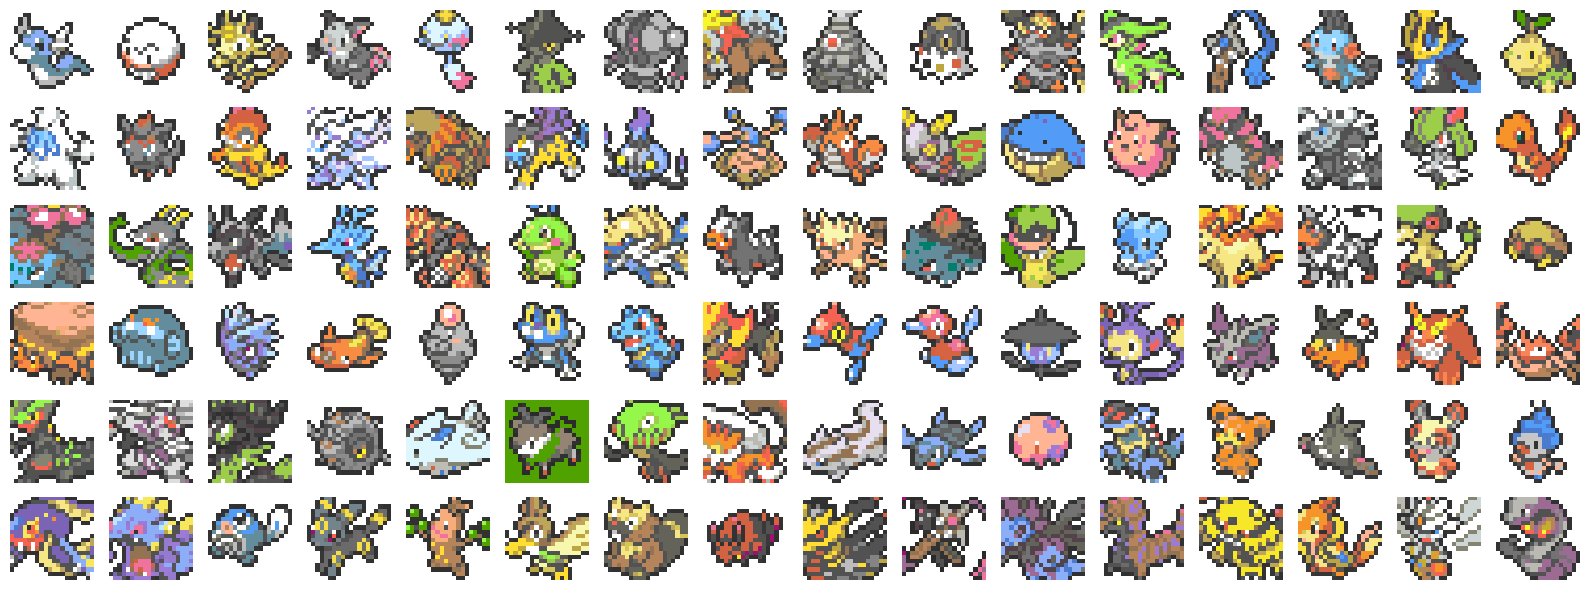

In [57]:
# Visualize train images
train_images = [pixel_to_image(data["pixel_color"], colormap) for data in pokemon_dataset["train"]]
show_images(train_images)

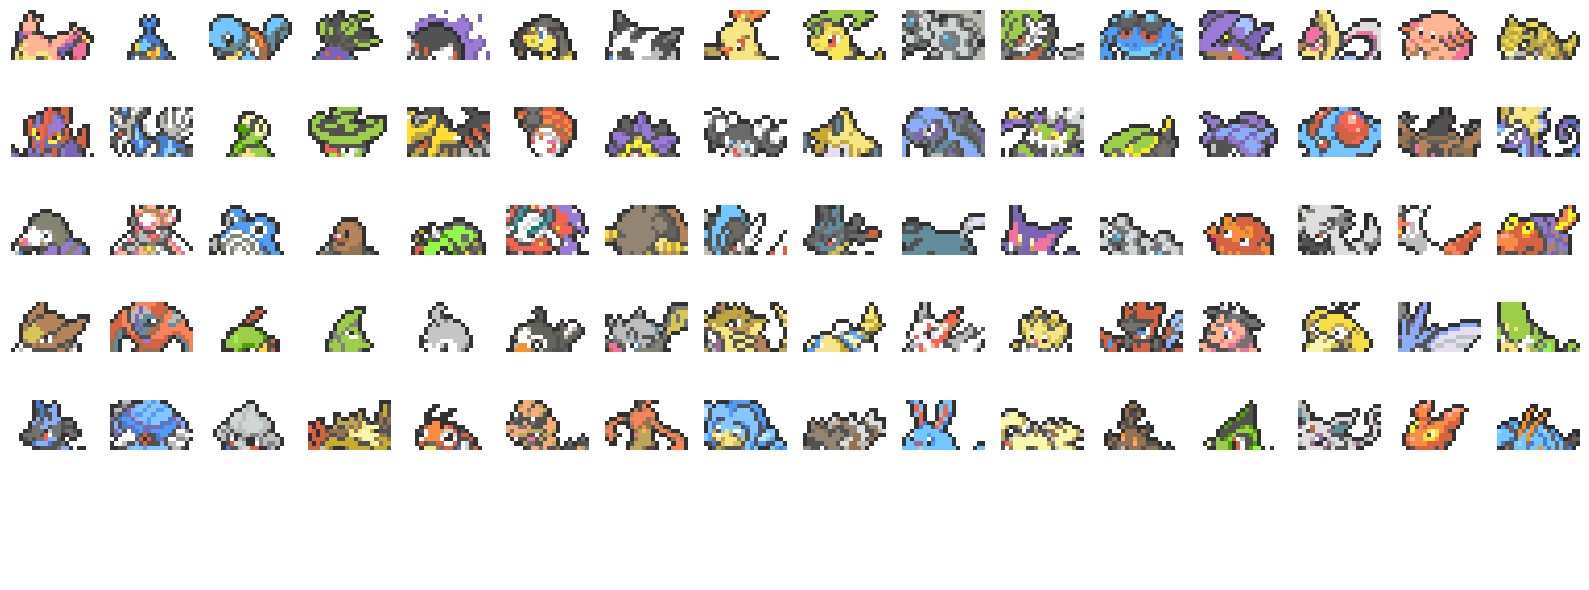

In [58]:
# Visualize test images
test_images = [pixel_to_image(data["pixel_color"], colormap) for data in pokemon_dataset["test"]]
show_images(test_images)

# Prepare Model

### Model Configuration
Here, we define the model configuration, including the architecture and key hyperparameters such as the number of attention heads, layers, embedding size, and more.
*   Hint 1: Adjust hyperparameters here for improved performance.
*   Hint 2: Experiment with different model architectures, such as Llama, Mistral, or Qwen, to enhance performance.
  * [LlamaConfig](https://huggingface.co/docs/transformers/model_doc/llama#transformers.LlamaConfig)
  * [MistralConfig](https://huggingface.co/docs/transformers/model_doc/mistral#transformers.MistralConfig)

There are lots of different model architectures can be used in this task, you can check other architectures from the "API --> Models --> text models" in the left panel.


In [59]:
# Define Llama model configuration
config = LlamaConfig(
    vocab_size=num_classes,           # Number of unique tokens in vocabulary (167 colors)
    hidden_size=384,                  # Embedding / hidden size
    intermediate_size=1024,           # SwiGLU MLP width (~8/3 * hidden_size)
    num_hidden_layers=8,              # Number of transformer layers
    num_attention_heads=6,            # Number of attention heads (head dim = 384 / 6 = 64)
    num_key_value_heads=6,            # Same as heads -> standard multi-head attention (no GQA)
    hidden_act="silu",                # Activation inside the SwiGLU MLP
    max_position_embeddings=400,      # Maximum sequence length (rotary embeddings, no learned position table)
    initializer_range=0.02,           # Standard deviation for weight initialization
    rms_norm_eps=1e-5,                # Small constant for RMSNorm numerical stability
    attention_dropout=0.3,            # Dropout on attention weights (Llama has no embedding/residual dropout)
    tie_word_embeddings=False,        # Separate input embedding and output head
    bos_token_id=None,                # Colors 1 and 2 are real pixels, so no special tokens
    eos_token_id=None,                # (default eos=2 would make generate() stop early)
    pad_token_id=None,                # Padding token ID (None means no padding token)
)

### Load Model

In [60]:
# Load the model using the configuration defined above
model = AutoModelForCausalLM.from_config(config)

print(model)

# Count trainable parameters
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"Trainable Parameters: {trainable_params:,}")

LlamaForCausalLM(
  (model): LlamaModel(
    (embed_tokens): Embedding(167, 384)
    (layers): ModuleList(
      (0-7): 8 x LlamaDecoderLayer(
        (self_attn): LlamaAttention(
          (q_proj): Linear(in_features=384, out_features=384, bias=False)
          (k_proj): Linear(in_features=384, out_features=384, bias=False)
          (v_proj): Linear(in_features=384, out_features=384, bias=False)
          (o_proj): Linear(in_features=384, out_features=384, bias=False)
        )
        (mlp): LlamaMLP(
          (gate_proj): Linear(in_features=384, out_features=1024, bias=False)
          (up_proj): Linear(in_features=384, out_features=1024, bias=False)
          (down_proj): Linear(in_features=1024, out_features=384, bias=False)
          (act_fn): SiLUActivation()
        )
        (input_layernorm): LlamaRMSNorm((384,), eps=1e-05)
        (post_attention_layernorm): LlamaRMSNorm((384,), eps=1e-05)
      )
    )
    (norm): LlamaRMSNorm((384,), eps=1e-05)
    (rotary_emb): LlamaRo

# Train and Inference

### Training Arguments
Here, we define the number of epochs for training, the learning rate, the optimizer, and the loss function.
*   Hint 3: Adjust the number of epochs and learning rate here to improve performance.

In [61]:
# Training Parameters
epochs = 30                                       # Number of training epochs
learning_rate = 3e-4                                 # Peak learning rate (linear warmup, then cosine decay)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")     # Check if CUDA is available for GPU
save_dir = "checkpoints"                               # Directory to save model checkpoints

# Loss function and optimizer
criterion = nn.CrossEntropyLoss()                          # Loss function for classification tasks
optimizer = optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=0.1) # AdamW optimizer with weight decay

# Learning-rate schedule: linear warmup, then cosine decay to 0, stepped once per batch
total_steps = epochs * len(train_dataloader)    # Total optimizer steps over the whole run
warmup_steps = int(0.05 * total_steps)          # Warm up over the first 5% of steps
def lr_lambda(step: int) -> float:
    """Multiplier on the peak learning rate at a given optimizer step."""
    if step < warmup_steps:
        return (step + 1) / warmup_steps         # Linear ramp from ~0 up to the peak
    progress = (step - warmup_steps) / max(1, total_steps - warmup_steps)
    return 0.5 * (1.0 + math.cos(math.pi * progress))  # Cosine from 1 down to 0
scheduler = optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)

### Save Model Function

In [62]:
def save_model(model: torch.nn.Module, optimizer: torch.optim.Optimizer, epoch: int, loss: float, save_dir: str, filename: str = "best_model.pth") -> None:
    """
    Saves the model state, optimizer state, current epoch, and loss to a specified directory.

    Args:
        model (torch.nn.Module): The PyTorch model to be saved.
        optimizer (torch.optim.Optimizer): The optimizer whose state will be saved.
        epoch (int): The current epoch number (used for checkpointing).
        loss (float): The current loss value to track model performance.
        save_dir (str): The directory where the model checkpoint will be saved.
        filename (str, optional): The name of the file to save the model. Defaults to "best_model.pth".

    Returns:
        None
    """
    # Construct the full path for saving the model checkpoint
    save_path = os.path.join(save_dir, filename)

    # Save the model, optimizer state, and additional metadata (epoch and loss)
    torch.save({
        'epoch': epoch + 1,                # Save epoch + 1 for easier tracking
        'model_state_dict': model.state_dict(),       # Save model weights
        'optimizer_state_dict': optimizer.state_dict(),  # Save optimizer state (important for resuming training)
        'loss': loss                     # Save the current loss value
    }, save_path)

    # Print a confirmation message indicating the model has been saved
    print(f"Model saved at {save_path} (Loss: {loss:.4f}, Epoch: {epoch + 1})")

### Train

We save the checkpoint with the lowest training loss since validation set reconstruction accuracy doesn't directly reflect the model's image generation quality.
*   Hint 4: Train a classifier to check if an image looks like a Pokémon or not. (Optional)

In [63]:
# Create save directory if it doesn't exist
os.makedirs(save_dir, exist_ok=True)
# Initialize best loss as positive infinity for comparison during model checkpointing
best_loss: float = float('inf')
# Move model to the appropriate device (GPU or CPU)
model.to(device)

# Training Loop
for epoch in range(epochs):
    model.train()  # Set the model to training mode
    epoch_loss = 0  # Initialize the epoch loss

    # Iterate over training data batches
    for input_ids, labels in tqdm(train_dataloader, desc=f"Training Epoch {epoch + 1}/{epochs}"):
        input_ids, labels = input_ids.to(device), labels.to(device)  # Move data to the same device as the model

        # Forward pass through the model to get logits (output probabilities)
        outputs = model(input_ids=input_ids).logits.view(-1, config.vocab_size)
        labels = labels.view(-1)  # Flatten labels to match logits shape

        # Calculate loss using CrossEntropyLoss
        loss = criterion(outputs, labels)

        # Backpropagation and optimizer step
        optimizer.zero_grad()  # Reset gradients to zero
        loss.backward()     # Compute gradients
        optimizer.step()     # Update model weights
        scheduler.step()     # Update learning rate (warmup + cosine decay)

        # Accumulate the loss for the epoch
        epoch_loss += loss.item()

    # Compute average epoch loss
    avg_epoch_loss = epoch_loss / len(train_dataloader)
    print(f"Epoch {epoch + 1}/{epochs}, Loss: {avg_epoch_loss:.4f}, LR: {scheduler.get_last_lr()[0]:.2e}")

    # Teacher-forced dev loss over all 399 positions (eval mode, no gradients)
    model.eval()
    dev_loss_total = 0
    with torch.no_grad():
        for input_ids, labels in dev_loss_dataloader:
            input_ids, labels = input_ids.to(device), labels.to(device)
            outputs = model(input_ids=input_ids).logits.view(-1, config.vocab_size)
            dev_loss_total += criterion(outputs, labels.view(-1)).item()
    avg_dev_loss = dev_loss_total / len(dev_loss_dataloader)
    print(f"Epoch {epoch + 1}/{epochs}, Dev Loss: {avg_dev_loss:.4f}")

    # Evaluation Loop (Validation)
    model.eval()      # Set the model to evaluation mode (disables dropout, etc.)
    total_accuracy = 0  # Initialize total accuracy
    num_batches = 0   # Initialize batch counter

    with torch.no_grad():  # Disable gradient calculation for validation
        # Iterate over validation data batches
        for inputs, labels in tqdm(dev_dataloader, desc="Evaluating"):
            inputs, labels = inputs.to(device), labels.to(device)  # Move validation data to device
            attention_mask = torch.ones_like(inputs)          # Attention mask to ensure valid token positions

            # Perform batch inference using the model
            generated_outputs = model.generate(inputs, attention_mask=attention_mask, max_length=400)

            # Extract the last 160 tokens from generated outputs and labels
            generated_outputs = generated_outputs[:, -160:]

            # Calculate accuracy for the batch
            accuracy = (generated_outputs == labels).float().mean().item()
            total_accuracy += accuracy
            num_batches += 1

    # Compute average reconstruction accuracy for the epoch
    avg_accuracy = total_accuracy / num_batches
    print(f"Epoch {epoch + 1}/{epochs}, Reconstruction Accuracy: {avg_accuracy:.4f}")

    # If the current epoch dev loss is better (lower) than the best dev loss, save the model
    if avg_dev_loss < best_loss:
        best_loss = avg_dev_loss                     # Update best dev loss
        save_model(model, optimizer, epoch, best_loss, save_dir)  # Save the model with the best dev loss

# Keep a copy of the best checkpoint on Google Drive so a later session can reload it without retraining
# (reload with: model.load_state_dict(torch.load(<path below>, weights_only=True, map_location=device)["model_state_dict"]))
try:
    import shutil
    drive_dir = "/content/drive/MyDrive/ece592_hw4"
    if os.path.isdir("/content/drive/MyDrive"):
        os.makedirs(drive_dir, exist_ok=True)
        shutil.copy(os.path.join(save_dir, "best_model.pth"), os.path.join(drive_dir, "best_model_flip_aug.pth"))
        print(f"Copied best checkpoint to {drive_dir}/best_model_flip_aug.pth")
    else:
        print("Google Drive is not mounted; checkpoint was not copied.")
except Exception as e:
    print(f"Could not copy checkpoint to Drive: {e}")

Training Epoch 1/30: 100%|██████████| 40/40 [00:13<00:00,  2.93it/s]


Epoch 1/30, Loss: 3.6770, LR: 2.05e-04
Epoch 1/30, Dev Loss: 3.2431


Evaluating: 100%|██████████| 5/5 [00:15<00:00,  3.16s/it]


Epoch 1/30, Reconstruction Accuracy: 0.3489
Model saved at checkpoints/best_model.pth (Loss: 3.2431, Epoch: 1)


Training Epoch 2/30: 100%|██████████| 40/40 [00:10<00:00,  3.64it/s]


...

Epoch 29/30, Reconstruction Accuracy: 0.3802


Training Epoch 30/30: 100%|██████████| 40/40 [00:11<00:00,  3.54it/s]


Epoch 30/30, Loss: 1.0204, LR: 0.00e+00
Epoch 30/30, Dev Loss: 1.5095


Evaluating: 100%|██████████| 5/5 [00:07<00:00,  1.53s/it]


Epoch 30/30, Reconstruction Accuracy: 0.3805
Copied best checkpoint to /content/drive/MyDrive/ece592_hw4/best_model_flip_aug.pth


### Inference

In [64]:
# Load the best model from the saved checkpoint
best_model_path = os.path.join(save_dir, "best_model.pth")              # Path to the best model checkpoint
checkpoint = torch.load(best_model_path, weights_only=True, map_location=device)  # Load checkpoint from the file
model.load_state_dict(checkpoint["model_state_dict"])                  # Load the model weights from checkpoint
model.eval()                                        # Set the model to evaluation mode (disables dropout, etc.)

# Testing Loop with Batch Inference
results: list = []  # List to store the generated sequences from the model
set_seed(0)  # Sampling is random; fix the seed so the generated file is reproducible

with torch.no_grad():  # Disable gradient calculations for inference
    # Iterate over test data in batches
    for inputs in tqdm(test_dataloader, desc="Generating Outputs"):
        inputs = inputs.to(device)         # Move model to the appropriate device (GPU or CPU)
        attention_mask = torch.ones_like(inputs)  # Attention mask (ensure valid token positions)

        # Generate predictions for the entire batch
        # Sample (instead of greedy decoding) so completions don't collapse into white / repeated runs
        generated_outputs = model.generate(inputs, attention_mask=attention_mask, max_length=400, do_sample=True, temperature=1.0, top_p=0.9, top_k=0)

        # Convert batch outputs to a list and append to results
        batch_results = generated_outputs.cpu().numpy().tolist()
        results.extend(batch_results)  # Extend the results list with batch results

# Save the results to a file
output_file: str = "reconstructed_results.txt"  # File to save the output sequences
with open(output_file, "w") as f:
    # Write each sequence to the file
    for seq in results:
        f.write(" ".join(map(str, seq)) + "\n")

print(f"Reconstructed results saved to {output_file}")  # Confirmation message

Generating Outputs: 100%|██████████| 5/5 [00:08<00:00,  1.68s/it]

Reconstructed results saved to reconstructed_results.txt


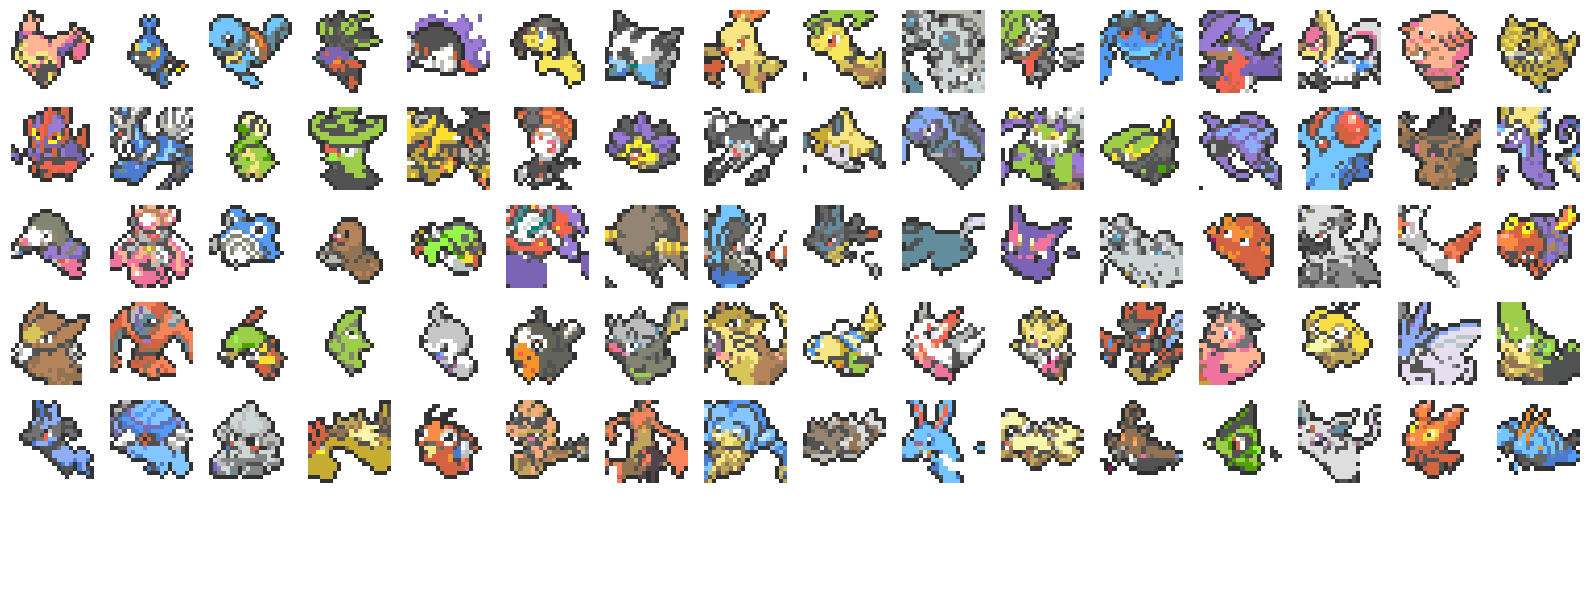

In [65]:
# Visualize generated test images
predicted_images = [pixel_to_image(sequence, colormap) for sequence in results]
show_images(predicted_images)

Don't forget to download your prediction file for submission, or you won't get your score!!

How to download files:

1. Check the file folder on the left hand side
2. If you finish your inference, you will find a .txt file (name can be modified in the inference block, default is reconstructed_results.txt)
3. Move to "more actions"
4. Click "Download"

In [66]:
# Print the submission file between markers so it can be extracted from the saved notebook
with open(output_file) as f:
    lines = f.read().splitlines()

bad = [i for i, l in enumerate(lines) if len(l.split()) != 400]
print(f"Lines: {len(lines)} (expected 80), lines without 400 ints: {len(bad)}")
print("===BEGIN_SUBMISSION===")
print("\n".join(lines))
print("===END_SUBMISSION===")

Lines: 80 (expected 80), lines without 400 ints: 0
===BEGIN_SUBMISSION===
0 0 0 0 1 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 33 34 2 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 16 33 71 33 34 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 33 33 33 34 0 0 0 0 0 0 0 1 2 0 0 0 0 0 0 5 33 33 33 2 0 0 0 0 0 0 0 1 33 34 2 0 0 0 2 151 66 66 31 10 79 0 0 0 1 2 2 33 71 66 36 2 0 0 2 151 31 33 33 33 66 10 2 2 33 33 33 66 66 103 121 149 2 0 2 105 33 33 33 33 33 33 71 33 33 33 66 66 103 32 38 121 149 0 22 44 121 33 33 33 33 33 66 33 33 66 151 151 55 66 66 36 0 1 68 121 33 33 33 33 33 33 33 33 151 151 151 55 66 66 66 36 0 1 121 105 121 33 33 121 121 121 33 33 71 151 5 2 66 66 66 36 0 23 121 44 121 121 121 68 68 44 121 33 66 2 0 5 38 66 36 0 0 0 23 121 68 121 121 121 66 121 105 121 66 2 0 0 1 2 0 0 0 0 0 23 121 66 105 66 68 68 105 32 66 16 0 0 0 0 0 0 0 0 0 0 23 38 47 105 105 105 32 105 2 0 0 0 0 0 0 0 0 0 0 0 0 23 33 85 105 105 74 47 1 0 0 0 0 0 0 0 0 0 0 0 0 0 1 68 105 68 121 5 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 5 105 47 5 0 0 0 0 0 

# Proxy Metrics (local PDR & FID)

The graders compute FID and PDR with their own tools, so the numbers below are **rough local stand-ins**. They are useful for comparing our own runs against each other, **not** for deciding whether a baseline threshold has been passed.

- **Proxy PDR:** a small CNN trained to tell real Pokémon (label 1) from real images whose bottom 40% was corrupted (label 0: a flat color, noise, or another image's tail). It is scored on the generated test images (`results` from the Inference cell).
- **Proxy FID:** Fréchet distance between Inception features of the generated images and the 712 real train + dev images. With only 80 generated images this estimate is noisy and biased, so reference points (a real-vs-real floor and a blank-bottom control) are printed next to it.
- Both are scored on whatever checkpoint the Inference cell loaded (`checkpoints/best_model.pth`, the lowest dev loss).

In [67]:
!pip install -q pytorch-fid

In [68]:
import torch.nn.functional as F
from pytorch_fid.inception import InceptionV3

TAIL_START = 240  # tokens 240-399 (bottom 40% of the 20x20 image) are what the model has to generate
cmap = np.array(colormap, dtype=np.uint8)  # token -> RGB lookup, shape (num_classes, 3)

train_seqs = np.array(pokemon_dataset["train"]["pixel_color"])  # (632, 400) real images
dev_seqs = np.array(pokemon_dataset["dev"]["pixel_color"])      # (80, 400) real images
gen_seqs = np.array(results)                                    # (80, 400) generated test images
assert train_seqs.shape[1] == dev_seqs.shape[1] == gen_seqs.shape[1] == 400

def to_rgb(seqs: np.ndarray) -> np.ndarray:
    """Token sequences (N, 400) -> RGB images (N, 20, 20, 3), uint8."""
    return cmap[seqs].reshape(len(seqs), 20, 20, 3)

def frechet_distance(f1: np.ndarray, f2: np.ndarray) -> float:
    """Fréchet distance between Gaussians fit to two sets of features (rows = samples).

    tr(sqrt(S1 S2)) is computed from the eigenvalues of S1 S2, which stays well-behaved when there
    are fewer samples than feature dimensions (80 vs 2048 here).
    """
    f1, f2 = f1.astype(np.float64), f2.astype(np.float64)
    mu1, mu2 = f1.mean(axis=0), f2.mean(axis=0)
    s1, s2 = np.cov(f1, rowvar=False), np.cov(f2, rowvar=False)
    eigvals = np.linalg.eigvals(s1 @ s2)
    tr_covmean = np.sqrt(np.clip(eigvals.real, 0, None)).sum()
    return float(((mu1 - mu2) ** 2).sum() + np.trace(s1) + np.trace(s2) - 2 * tr_covmean)

# Inception-v3 pool features (2048-d), the same network family the FID metric uses
inception = InceptionV3([InceptionV3.BLOCK_INDEX_BY_DIM[2048]]).to(device).eval()

@torch.no_grad()
def inception_features(seqs: np.ndarray, batch_size: int = 64) -> np.ndarray:
    """Token sequences -> (N, 2048) Inception features (images are resized to 299x299 internally)."""
    feats = []
    for i in range(0, len(seqs), batch_size):
        x = torch.from_numpy(to_rgb(seqs[i:i + batch_size])).float().div(255).permute(0, 3, 1, 2).to(device)
        feats.append(inception(x)[0].squeeze(-1).squeeze(-1).cpu().numpy())
    return np.concatenate(feats)

In [69]:
rng = np.random.default_rng(0)
torch.manual_seed(0)

def corrupt(seq: np.ndarray, kind: int, rng: np.random.Generator) -> np.ndarray:
    """Copy of a real image whose bottom 40% is replaced, giving a 'not a Pokémon' example.

    kind 0: one flat color (taken from the image itself)
    kind 1: noise (pixels drawn at random from the image's own top 60%)
    kind 2: the bottom of a different real training image
    """
    out = seq.copy()
    prefix = seq[:TAIL_START]
    if kind == 0:
        out[TAIL_START:] = rng.choice(prefix)
    elif kind == 1:
        out[TAIL_START:] = rng.choice(prefix, size=len(seq) - TAIL_START)
    else:
        out[TAIL_START:] = train_seqs[rng.integers(len(train_seqs))][TAIL_START:]
    return out

class PokemonDetector(nn.Module):
    """Small CNN on 20x20 RGB images -> one logit (positive = looks like a real Pokémon)."""
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),    # -> 10x10
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(), nn.MaxPool2d(2),  # -> 5x5
        )
        self.head = nn.Sequential(nn.Flatten(), nn.Dropout(0.3), nn.Linear(128 * 5 * 5, 1))

    def forward(self, x):
        return self.head(self.features(x)).squeeze(-1)

def to_tensor(seqs: np.ndarray) -> torch.Tensor:
    return torch.from_numpy(to_rgb(seqs)).float().div(255).permute(0, 3, 1, 2)

detector = PokemonDetector().to(device)
det_optimizer = optim.AdamW(detector.parameters(), lr=1e-3, weight_decay=1e-2)
det_criterion = nn.BCEWithLogitsLoss()
det_epochs = 30

for epoch in range(det_epochs):
    detector.train()
    # Real images (label 1) + a fresh random corruption of each one (label 0), reshuffled every epoch
    negatives = np.stack([corrupt(s, int(rng.integers(3)), rng) for s in train_seqs])
    x_all = np.concatenate([train_seqs, negatives])
    y_all = np.concatenate([np.ones(len(train_seqs)), np.zeros(len(negatives))])
    order = rng.permutation(len(x_all))
    epoch_loss = 0.0
    for i in range(0, len(x_all), 64):
        idx = order[i:i + 64]
        xb = to_tensor(x_all[idx]).to(device)
        yb = torch.from_numpy(y_all[idx]).float().to(device)
        det_loss = det_criterion(detector(xb), yb)
        det_optimizer.zero_grad()
        det_loss.backward()
        det_optimizer.step()
        epoch_loss += det_loss.item() * len(idx)
    if (epoch + 1) % 5 == 0:
        print(f"Detector epoch {epoch + 1}/{det_epochs}, Loss: {epoch_loss / len(x_all):.4f}")

@torch.no_grad()
def detector_probs(seqs: np.ndarray) -> np.ndarray:
    """Probability that each image (rows of token ids) looks like a real Pokémon."""
    detector.eval()
    return torch.sigmoid(detector(to_tensor(seqs).to(device))).cpu().numpy()

# Sanity checks on held-out dev images: the detector should accept real ones and reject corrupted ones
print(f"Real dev images judged Pokémon:                {(detector_probs(dev_seqs) > 0.5).mean():.3f}  (want ~1)")
for kind, name in enumerate(["flat color", "noise", "swapped tail"]):
    corrupted = np.stack([corrupt(s, kind, rng) for s in dev_seqs])
    print(f"Corrupted dev ({name:12s}) judged NOT Pokémon: {(detector_probs(corrupted) <= 0.5).mean():.3f}  (want ~1)")

Detector epoch 5/30, Loss: 0.3961
Detector epoch 10/30, Loss: 0.2188
Detector epoch 15/30, Loss: 0.1243
Detector epoch 20/30, Loss: 0.0801
Detector epoch 25/30, Loss: 0.0826
Detector epoch 30/30, Loss: 0.0690
Real dev images judged Pokémon:                0.900  (want ~1)
Corrupted dev (flat color  ) judged NOT Pokémon: 0.988  (want ~1)
Corrupted dev (noise       ) judged NOT Pokémon: 1.000  (want ~1)
Corrupted dev (swapped tail) judged NOT Pokémon: 0.900  (want ~1)


In [70]:
# Control: the given 60% prefix followed by a blank white bottom, i.e. an obviously unfinished image
blank_seqs = gen_seqs.copy()
blank_seqs[:, TAIL_START:] = 0

f_train = inception_features(train_seqs)
f_dev = inception_features(dev_seqs)
f_ref = np.concatenate([f_train, f_dev])  # real reference set: 712 images
f_gen = inception_features(gen_seqs)
f_blank = inception_features(blank_seqs)

gen_probs = detector_probs(gen_seqs)

print("=" * 66)
print("PROXY METRICS (local stand-ins, compare runs with each other only)")
print("=" * 66)
print(f"Proxy PDR  generated test images          : {(gen_probs > 0.5).mean():.3f}   (mean prob {gen_probs.mean():.3f})")
print(f"Proxy PDR  control: blank-white bottom    : {(detector_probs(blank_seqs) > 0.5).mean():.3f}   (should be low)")
print(f"Proxy PDR  ceiling: real dev images       : {(detector_probs(dev_seqs) > 0.5).mean():.3f}   (should be ~1)")
print(f"Proxy FID  generated vs real (712)        : {frechet_distance(f_gen, f_ref):.2f}")
print(f"Proxy FID  control: blank-white bottom    : {frechet_distance(f_blank, f_ref):.2f}   (should be worse than generated)")
print(f"Proxy FID  floor: real dev vs real train  : {frechet_distance(f_dev, f_train):.2f}   (n=80 noise floor, best case)")
print("=" * 66)

PROXY METRICS (local stand-ins, compare runs with each other only)
Proxy PDR  generated test images          : 0.887   (mean prob 0.839)
Proxy PDR  control: blank-white bottom    : 0.000   (should be low)
Proxy PDR  ceiling: real dev images       : 0.900   (should be ~1)
Proxy FID  generated vs real (712)        : 65.40
Proxy FID  control: blank-white bottom    : 101.77   (should be worse than generated)
Proxy FID  floor: real dev vs real train  : 63.76   (n=80 noise floor, best case)


# Decoding Experiment: Sampling vs. Greedy

Loads the checkpoint saved during training (`checkpoints/best_model.pth`, lowest dev loss) and regenerates the test completions with **sampling** instead of greedy decoding. Two settings, two random seeds each:

- `6a`: temperature 0.8, top-k 50 (mild)
- `6b`: temperature 1.0, top-p 0.9 (nucleus; top-k disabled so only top-p applies)

Each result is printed between `===BEGIN_SUBMISSION:<label>===` markers so `extract_submission.py --label <label>` can pull it out. The greedy output from the Inference cell is not changed.

In [71]:
# Load the saved checkpoint (lowest dev loss) and put the model in eval mode
checkpoint = torch.load(os.path.join(save_dir, "best_model.pth"), weights_only=True, map_location=device)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()
print(f"Loaded checkpoint from epoch {checkpoint['epoch']} (dev loss {checkpoint['loss']:.4f})")

# Sampling settings to compare (generate() defaults to top_k=50, so top_k=0 is set to disable it for 6b)
sampling_settings = {
    "6a": dict(temperature=0.8, top_k=50),
    "6b": dict(temperature=1.0, top_p=0.9, top_k=0),
}
sampling_seeds = [0, 1]

sampled_results: dict = {}  # label -> list of 80 generated sequences
for setting_name, gen_kwargs in sampling_settings.items():
    for seed in sampling_seeds:
        set_seed(seed)  # make each (setting, seed) run repeatable
        label = f"{setting_name}_s{seed}"
        generated: list = []
        with torch.no_grad():
            for inputs in tqdm(test_dataloader, desc=f"Sampling {label}"):
                inputs = inputs.to(device)
                attention_mask = torch.ones_like(inputs)
                outputs = model.generate(inputs, attention_mask=attention_mask, max_length=400, do_sample=True, **gen_kwargs)
                generated.extend(outputs.cpu().numpy().tolist())
        assert len(generated) == 80 and all(len(seq) == 400 for seq in generated), label
        sampled_results[label] = generated
print(f"Generated: {list(sampled_results)}")

Loaded checkpoint from epoch 18 (dev loss 1.4685)


Sampling 6b_s1: 100%|██████████| 5/5 [00:08<00:00,  1.62s/it]

Generated: ['6a_s0', '6a_s1', '6b_s0', '6b_s1']


In [72]:
# Print each sampled result between labeled markers so it can be extracted from the saved notebook
for label, sequences in sampled_results.items():
    print(f"===BEGIN_SUBMISSION:{label}===")
    for seq in sequences:
        print(" ".join(map(str, seq)))
    print(f"===END_SUBMISSION:{label}===")

===BEGIN_SUBMISSION:6a_s0===
0 0 0 0 1 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 33 34 2 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 16 33 71 33 34 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 33 33 33 34 0 0 0 0 0 0 0 1 2 0 0 0 0 0 0 5 33 33 33 2 0 0 0 0 0 0 0 1 33 34 2 0 0 0 2 151 66 66 31 10 79 0 0 0 1 2 2 33 71 66 36 2 0 0 2 151 31 33 33 33 66 10 2 2 33 33 33 66 66 103 121 149 2 0 2 105 33 33 33 33 33 33 71 33 33 33 66 66 103 32 38 121 149 0 22 44 121 33 33 33 33 33 66 33 33 66 151 151 55 66 66 36 0 1 68 121 33 33 33 33 33 33 33 33 151 151 151 55 66 66 66 36 0 1 121 105 121 33 33 121 121 121 33 33 71 151 5 2 66 66 66 36 0 23 121 44 121 121 121 68 68 44 121 33 66 2 0 5 38 66 36 0 0 0 23 121 121 121 121 121 66 121 105 121 66 2 0 0 1 2 0 0 0 0 0 23 121 121 105 66 68 68 105 32 66 16 0 0 0 0 0 0 0 0 0 0 23 105 47 105 105 105 32 105 2 0 0 0 0 0 0 0 0 0 0 0 0 11 68 85 105 105 105 47 1 0 0 0 0 0 0 0 0 0 0 0 0 0 16 68 105 68 121 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 5 105 47 121 23 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 23 5 23 0 0 0